In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

X, y = load_iris(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print(f"Accuracy: {rf.score(X_test, y_test):.4f}")
print(f"Feature importances: {rf.feature_importances_}")

Accuracy: 1.0000
Feature importances: [0.10968334 0.02954459 0.43763486 0.42313721]


Accuracy: 0.9211
Feature importances: [0.11504762 0.02402532 0.43276876 0.42815829]


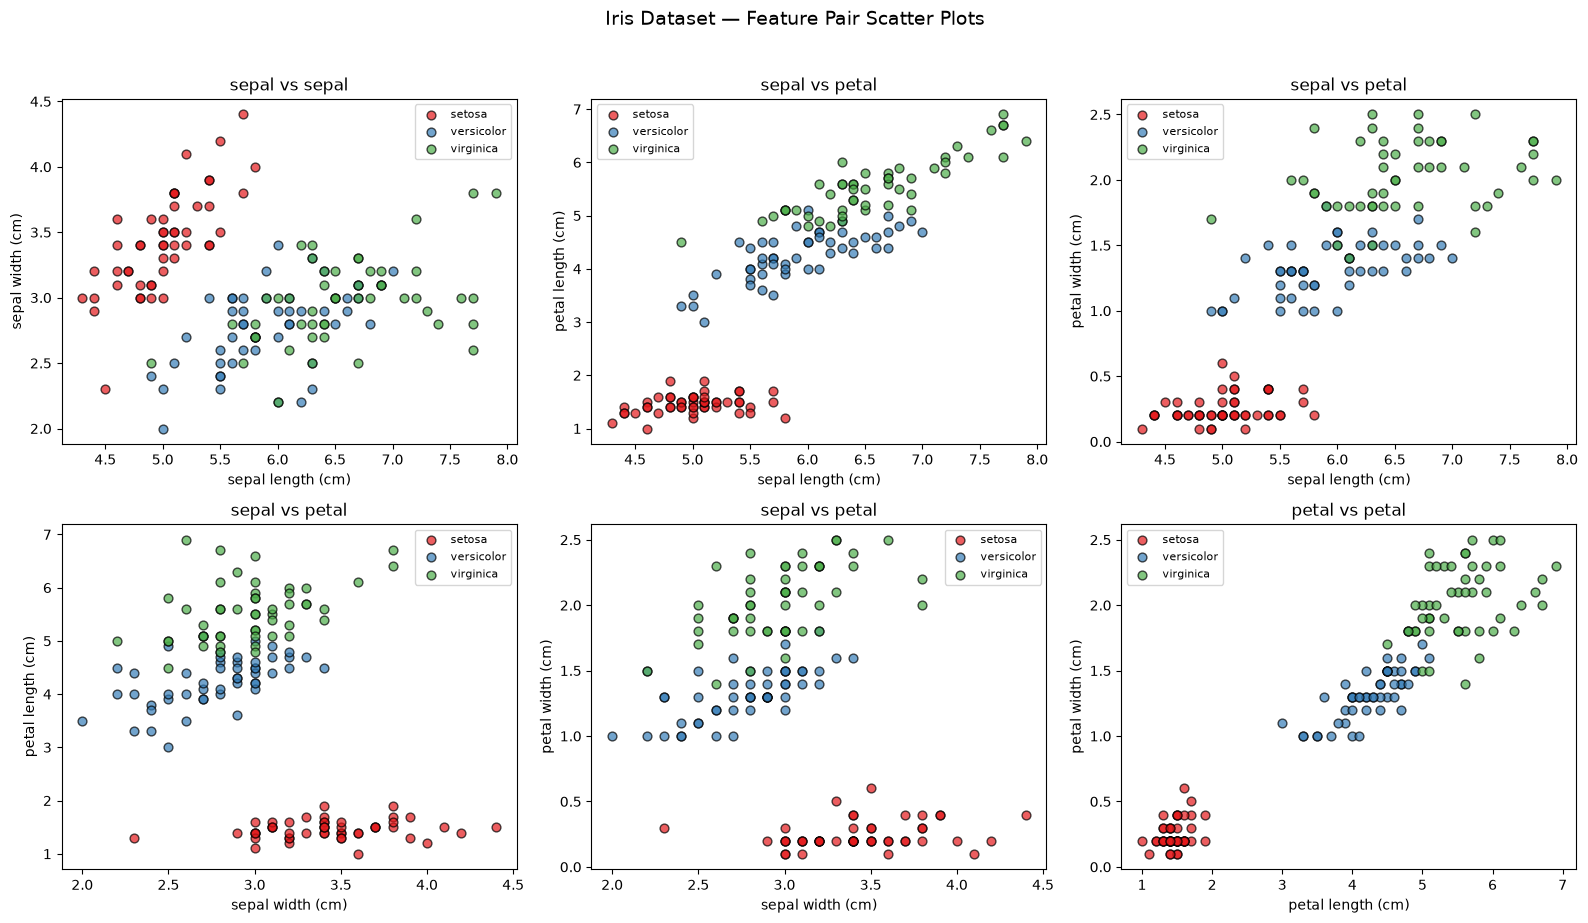

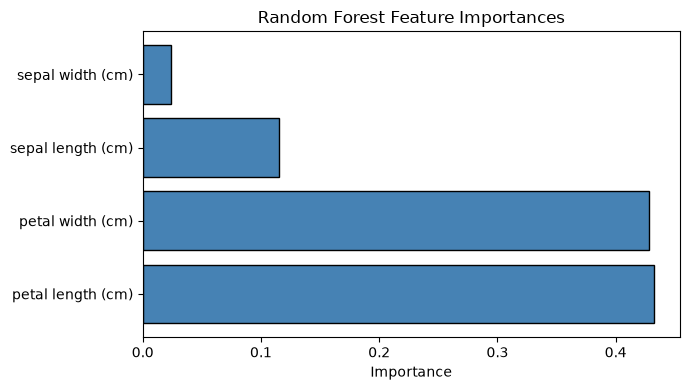

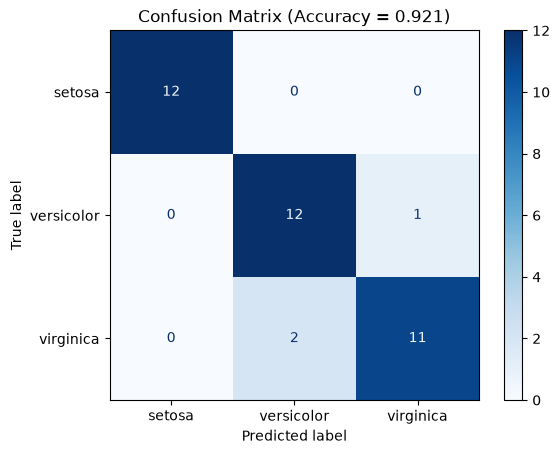

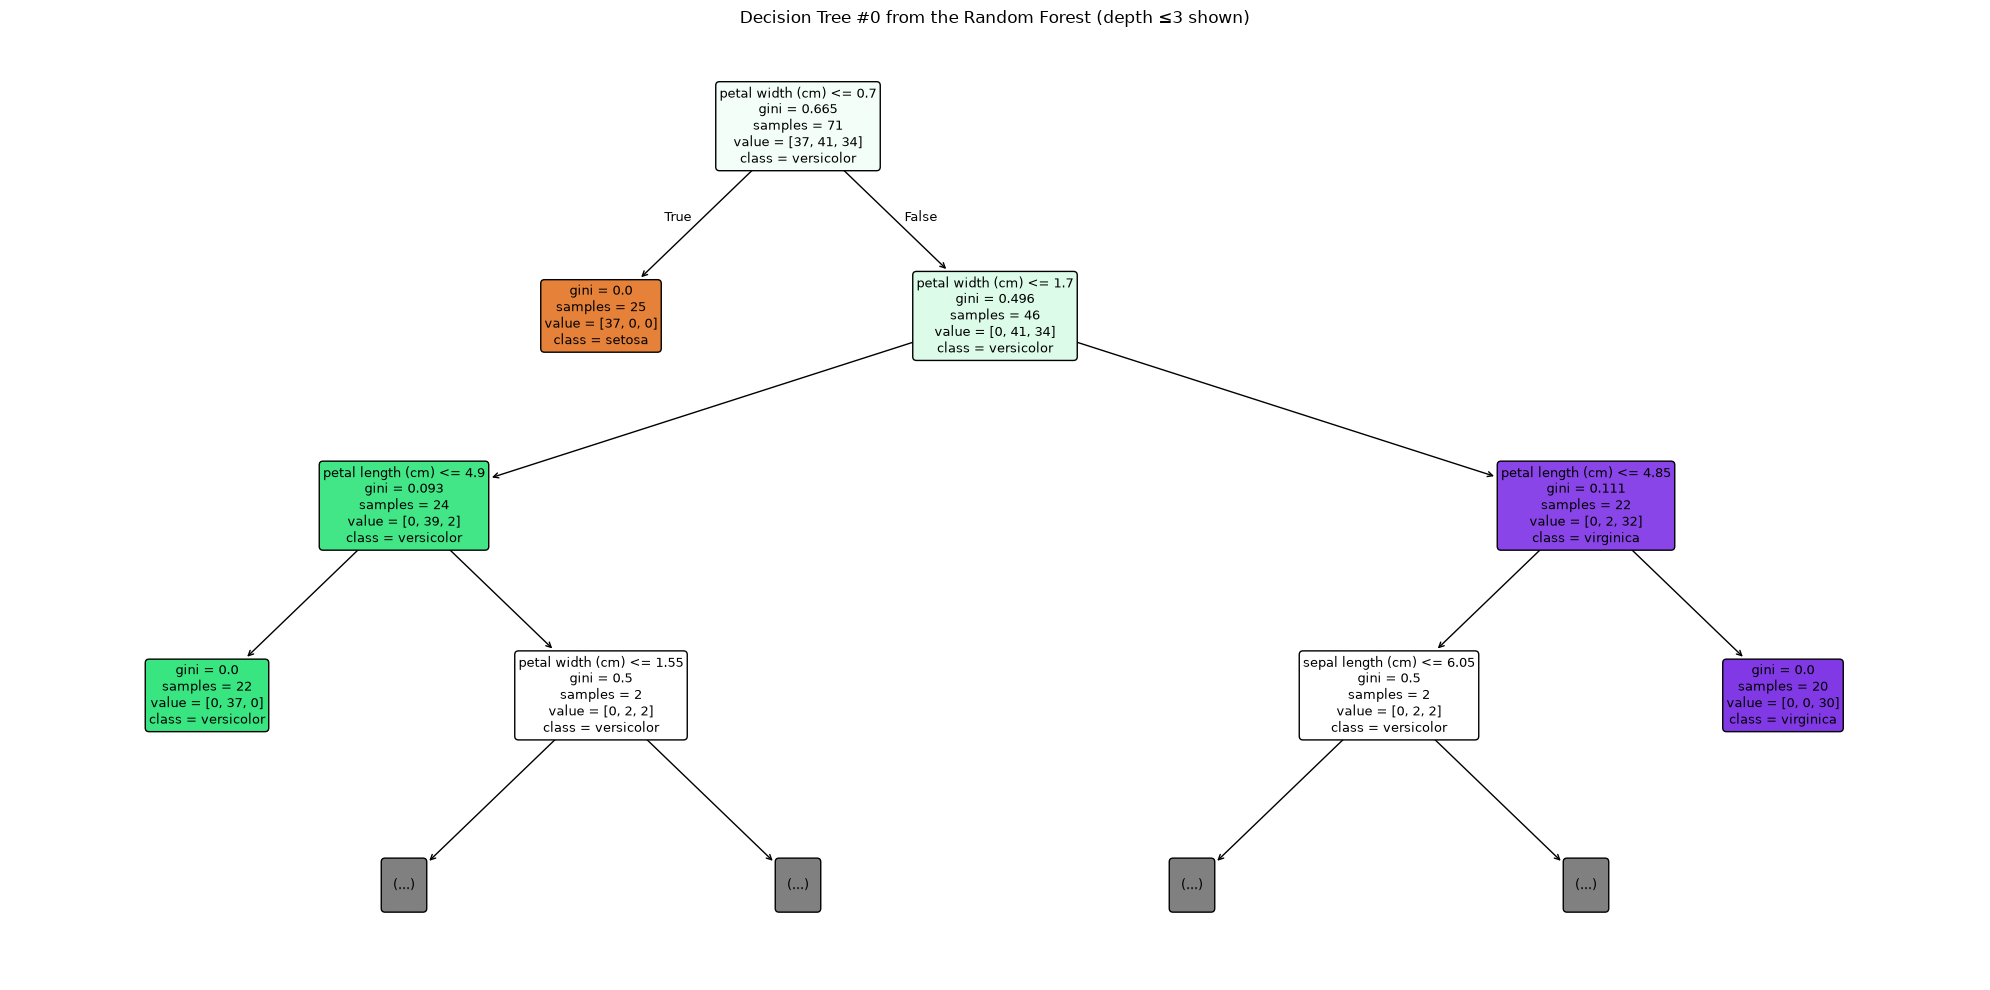

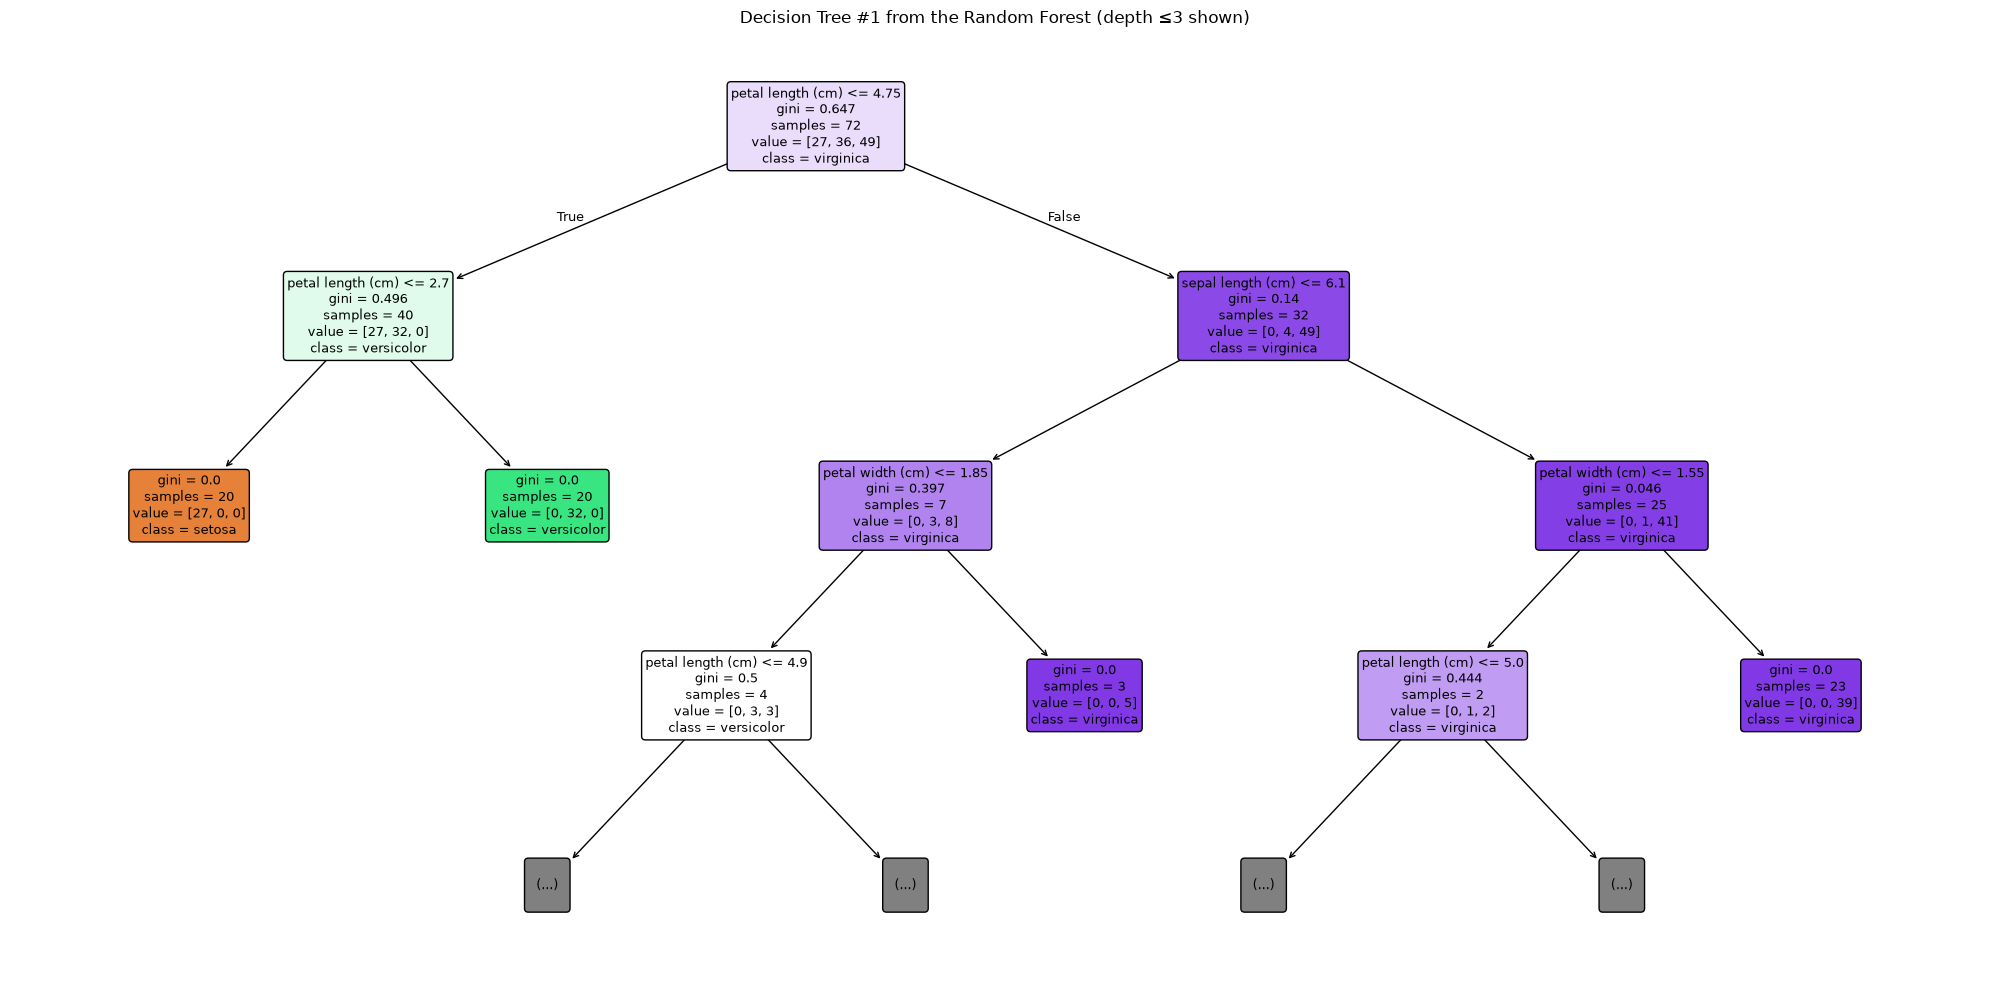

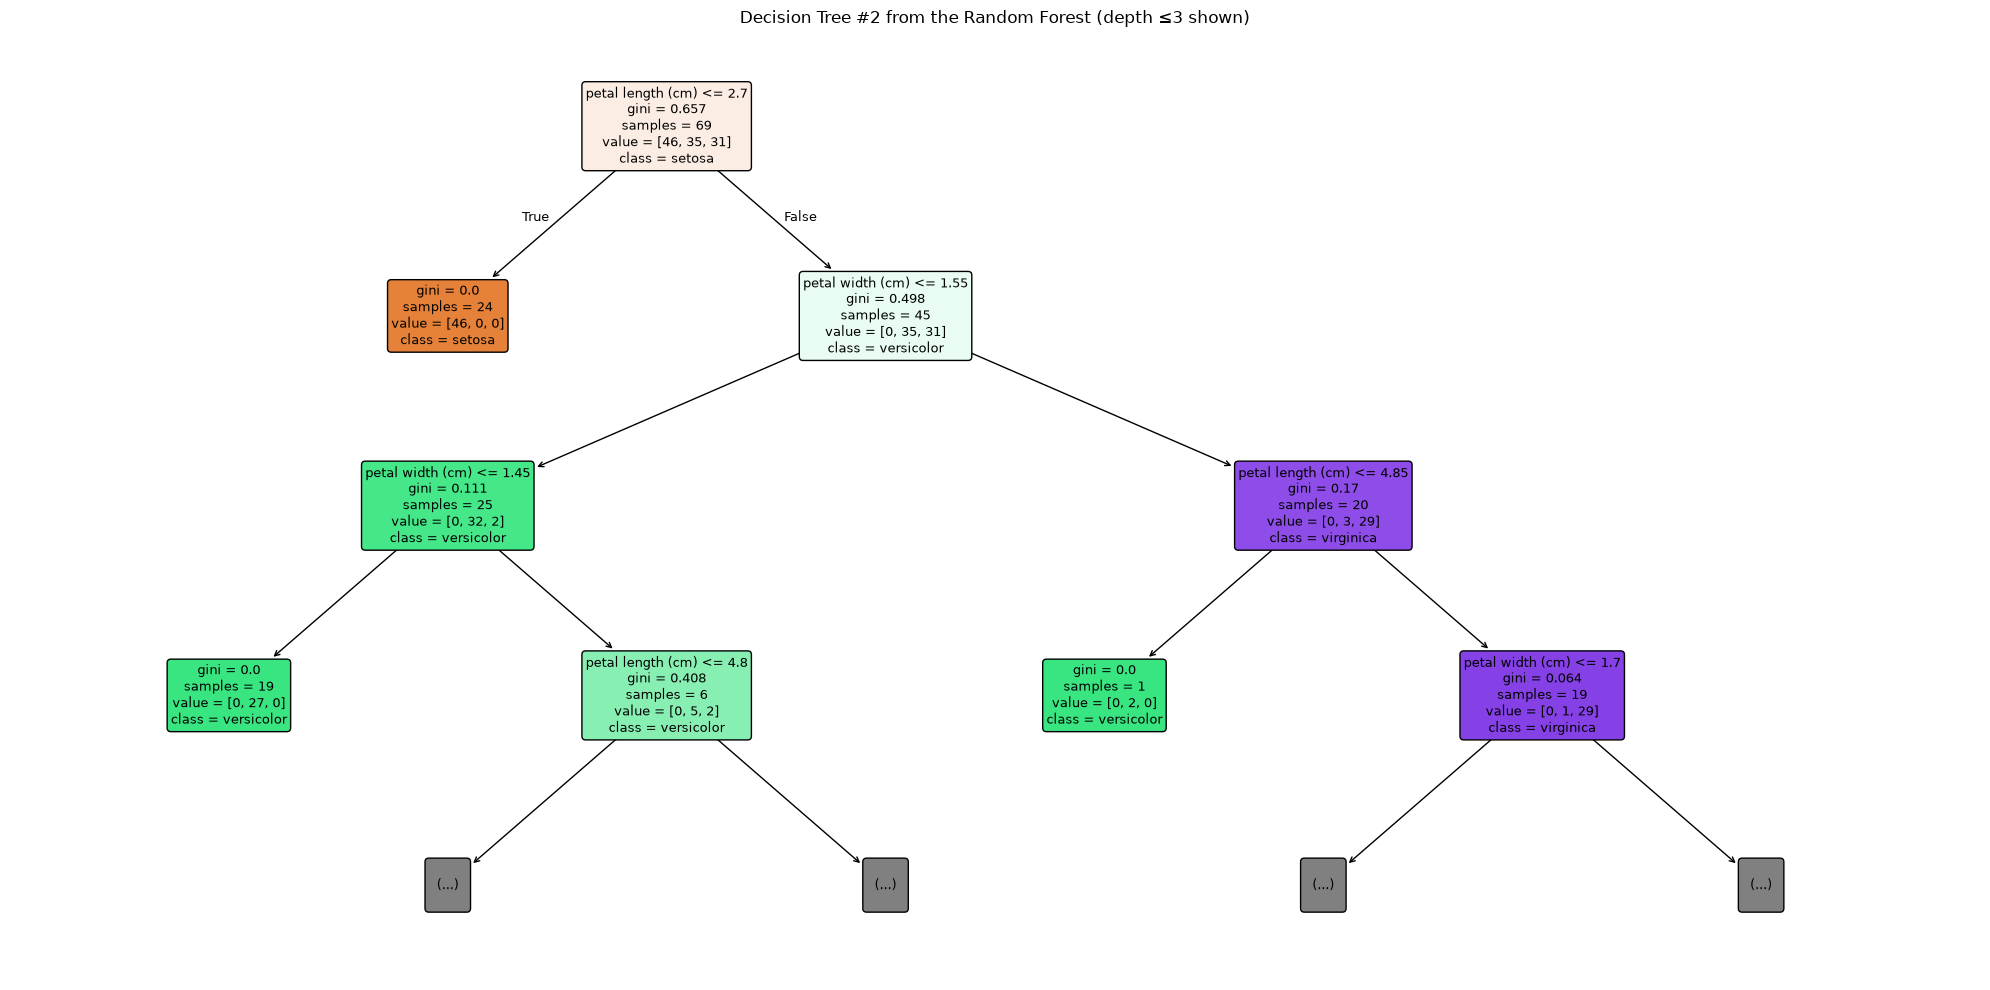

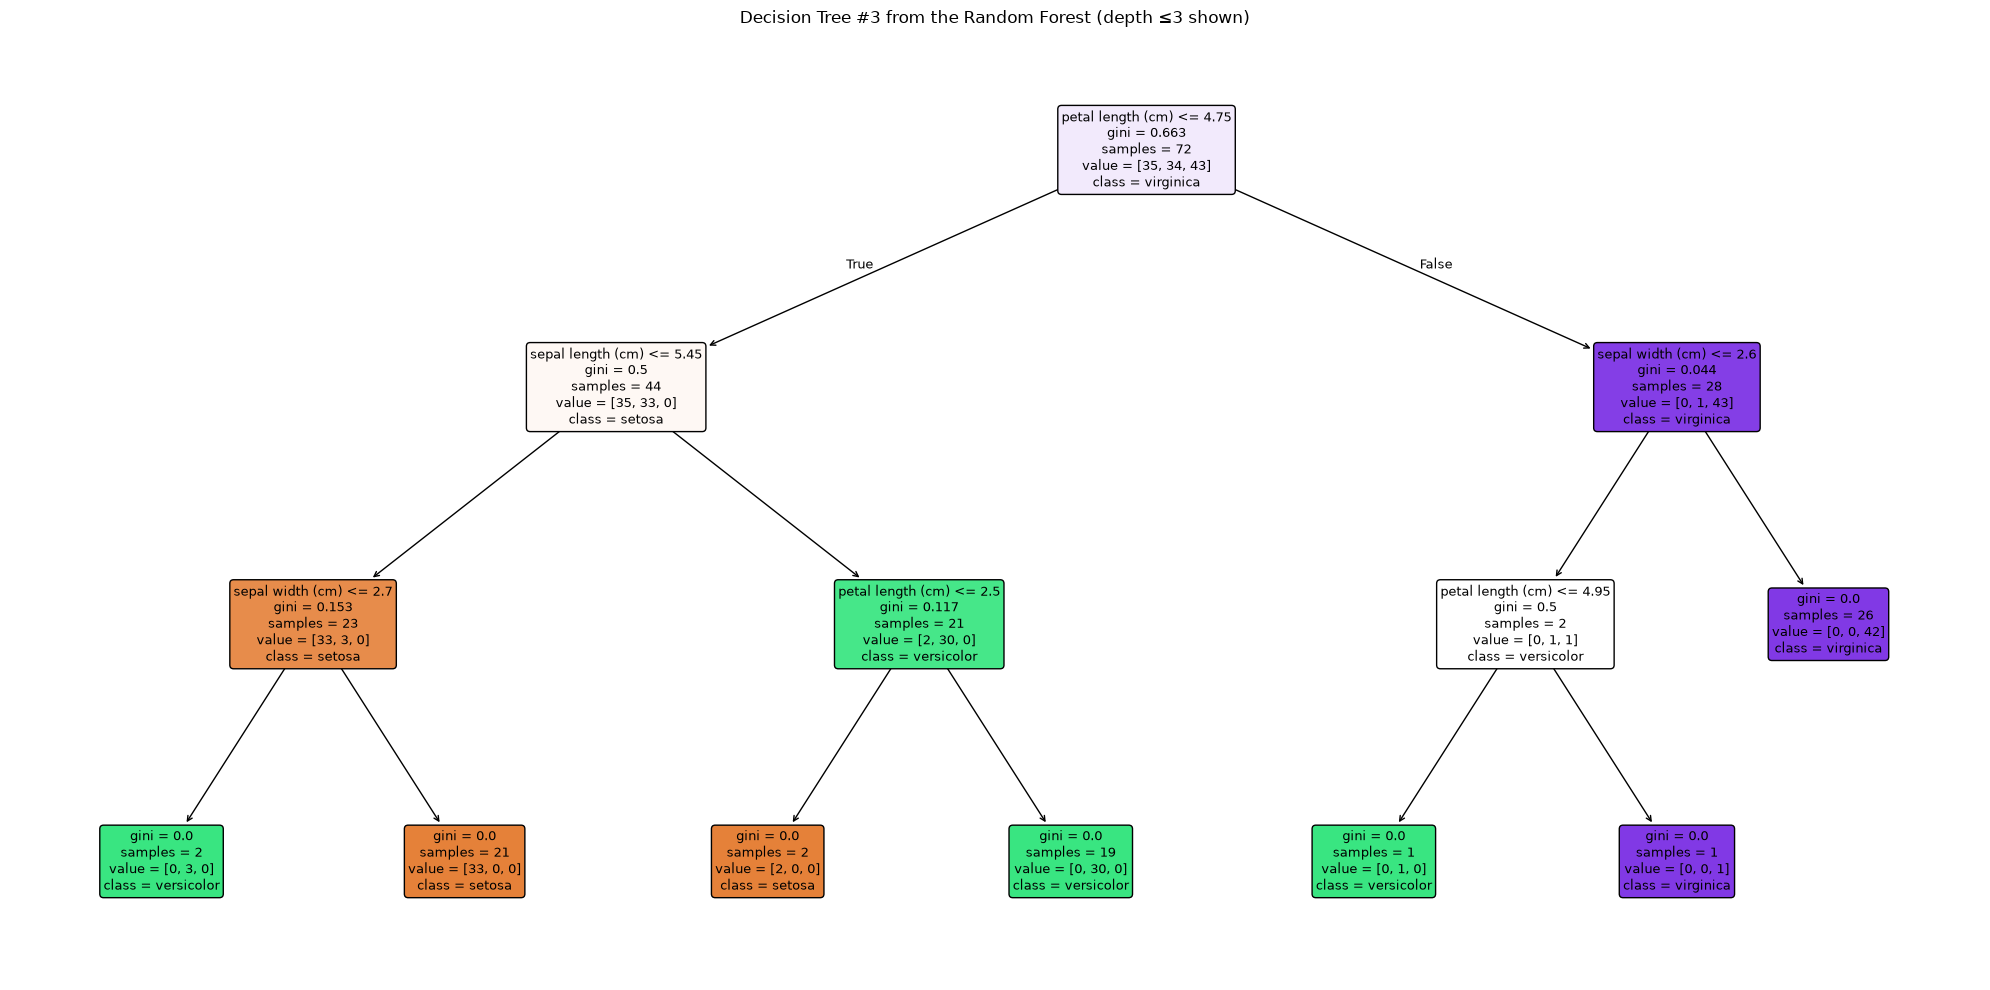

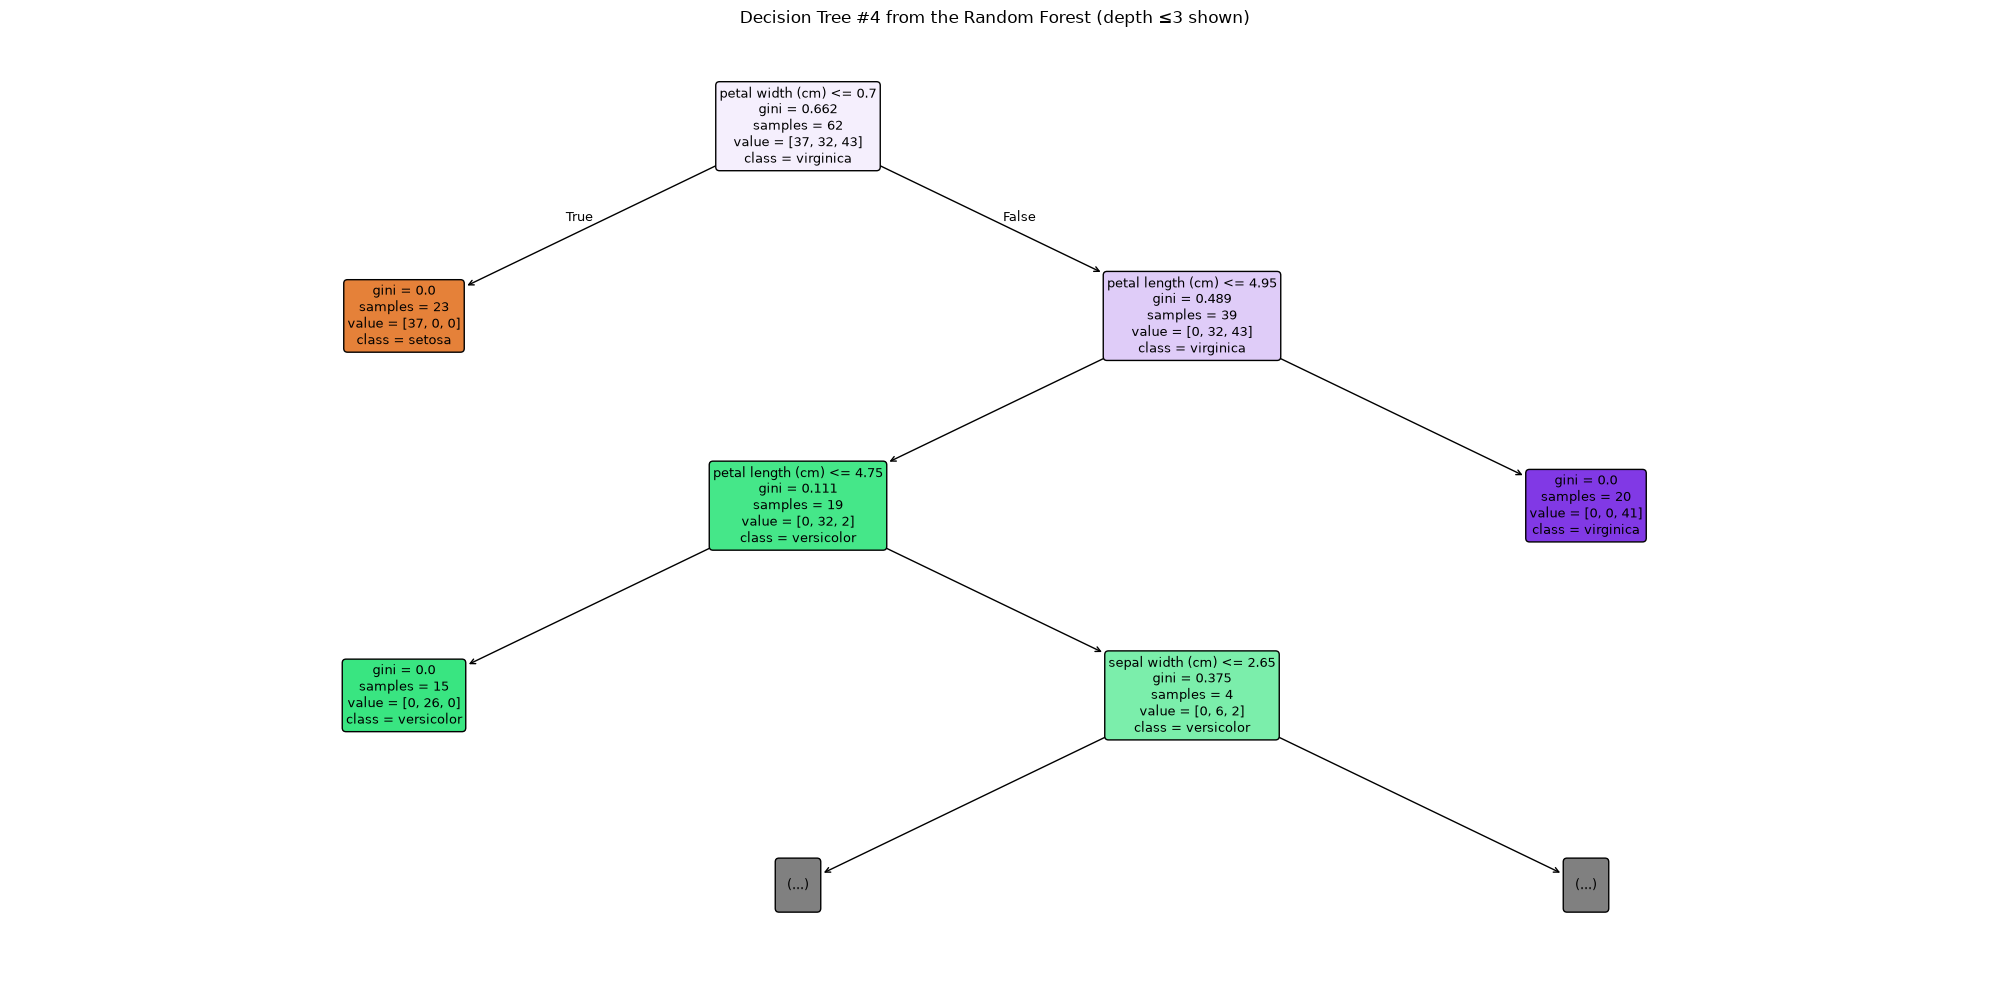

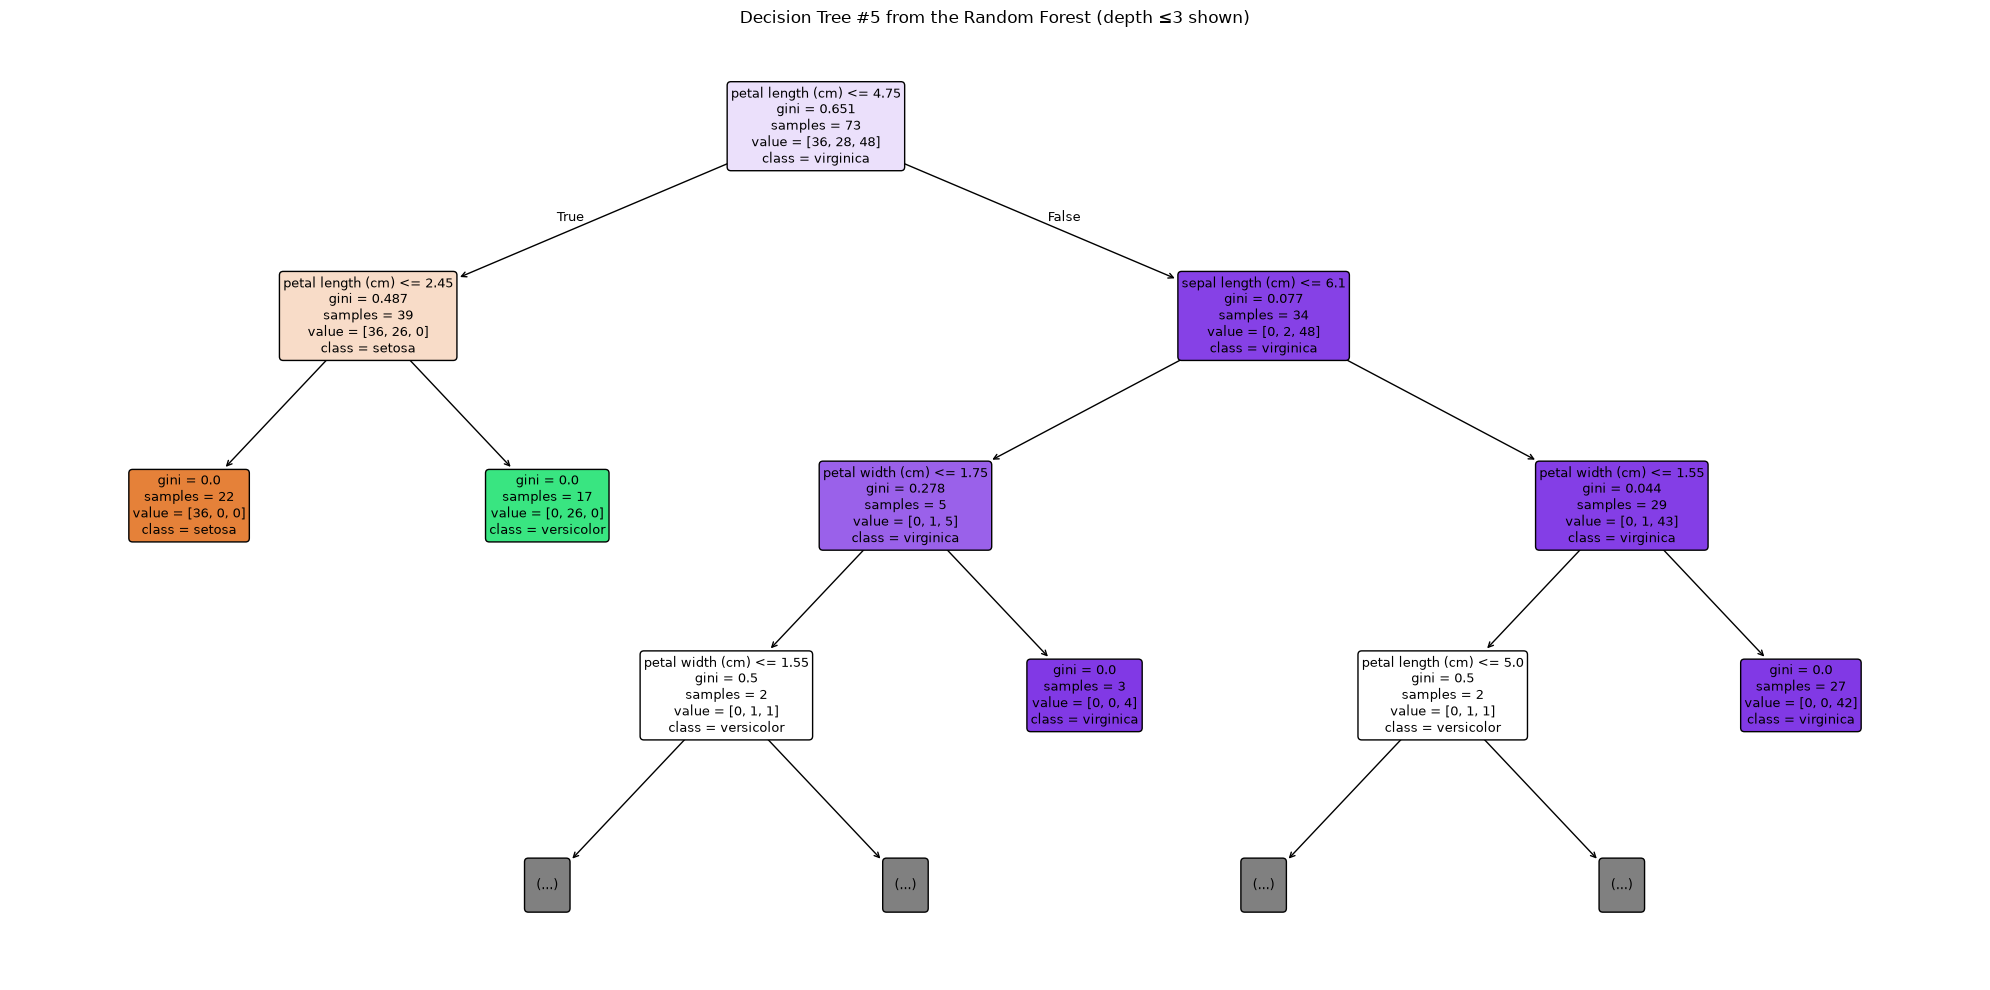

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import plot_tree

# ---------- Data ----------
iris = load_iris()
X, y = iris.data, iris.target
feature_names = iris.feature_names
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, stratify=y
)

# ---------- Model ----------
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
print(f"Accuracy: {rf.score(X_test, y_test):.4f}")
print(f"Feature importances: {rf.feature_importances_}")

# ---------- 1. Data Visualization ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

# Scatter plots for feature pairs (colored by class)
pairs = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
colors = ['#e41a1c', '#377eb8', '#4daf4a']

for ax, (i, j) in zip(axes, pairs):
    for cls in range(3):
        mask = y == cls
        ax.scatter(X[mask, i], X[mask, j], s=40, alpha=0.7,
                   color=colors[cls], label=class_names[cls], edgecolor='k')
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel(feature_names[j])
    ax.set_title(f"{feature_names[i].split()[0]} vs {feature_names[j].split()[0]}")
    ax.legend(fontsize=8)

plt.suptitle("Iris Dataset — Feature Pair Scatter Plots", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ---------- 2. Feature Importances ----------
fig, ax = plt.subplots(figsize=(7, 4))
order = np.argsort(rf.feature_importances_)[::-1]
ax.barh([feature_names[i] for i in order],
        rf.feature_importances_[order], color='steelblue', edgecolor='k')
ax.set_xlabel("Importance")
ax.set_title("Random Forest Feature Importances")
plt.tight_layout()
plt.show()

# ---------- 3. Confusion Matrix ----------
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
y_pred = rf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap='Blues', values_format='d')
plt.title(f"Confusion Matrix (Accuracy = {rf.score(X_test, y_test):.3f})")
plt.show()

# ---------- 4. Decision Tree Split Visualization ----------
# Plot a few trees from the forest (each is a full decision tree)
for idx in [0, 1, 2,3,4,5]:
    fig, ax = plt.subplots(figsize=(20, 10))
    plot_tree(rf.estimators_[idx],
              feature_names=feature_names,
              class_names=class_names,
              filled=True, rounded=True, max_depth=3, fontsize=9, ax=ax)
    ax.set_title(f"Decision Tree #{idx} from the Random Forest (depth ≤3 shown)")
    plt.tight_layout()
    plt.show()

In [8]:
for idx in range(6):
    tree = rf.estimators_[idx]
    depth = tree.get_depth()          # actual depth reached
    leaves = tree.get_n_leaves()
    print(f"Tree #{idx}: depth = {depth}, leaves = {leaves}")

Tree #0: depth = 4, leaves = 7
Tree #1: depth = 6, leaves = 10
Tree #2: depth = 5, leaves = 8
Tree #3: depth = 3, leaves = 7
Tree #4: depth = 6, leaves = 7
Tree #5: depth = 4, leaves = 8


min=2, max=8, mean=4.6


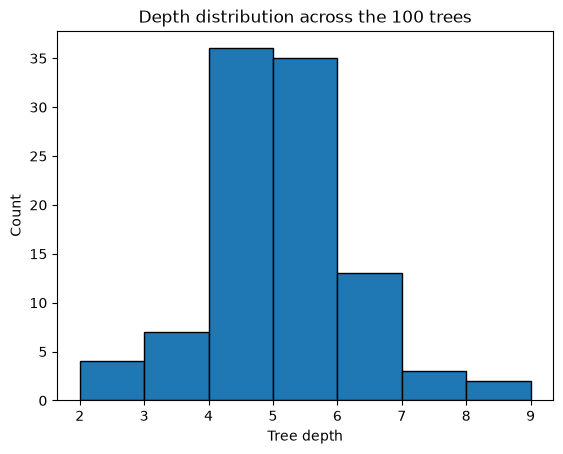

In [9]:
depths = [t.get_depth() for t in rf.estimators_]
print(f"min={min(depths)}, max={max(depths)}, mean={np.mean(depths):.1f}")
plt.hist(depths, bins=range(min(depths), max(depths)+2), edgecolor='k')
plt.xlabel("Tree depth"); plt.ylabel("Count")
plt.title("Depth distribution across the 100 trees")
plt.show()